In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
df = pd.read_csv("/content/drive/MyDrive/offerlater/adult.csv")

In [5]:
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [4]:
df.describe()

,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


In [6]:
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

# 1. Clean data: Replace '?' with NaN and drop missing values
df_cleaned = df.replace('?', np.nan).dropna()

# 2. Separate Features, Target, and the Sensitive Attribute ('sex')
# Target column: income (binary: >50K or <=50K)
y = df_cleaned['income'].apply(lambda x: 1 if '>50K' in str(x) else 0)

# Save the sensitive attribute 'sex' for evaluation
sex_attr = df_cleaned['sex']

# Drop target and 'sex' from our training features to avoid direct training on gender
X = df_cleaned.drop(columns=['income', 'sex'])

# Identify numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object', 'category']).columns.tolist()

print(f"Numeric features: {numeric_features}")
print(f"Categorical features: {categorical_features}")

Numeric features: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Categorical features: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'native.country']


In [7]:
# 3. Split the data into train and test sets, maintaining the aligned indices for 'sex'
X_train, X_test, y_train, y_test, sex_train, sex_test = train_test_split(
    X, y, sex_attr, test_size=0.2, random_state=42, stratify=y
)

# 4. Create Preprocessing Pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_features),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_features)
    ]
)

# 5. Define and Train the Logistic Regression Model within a Pipeline
model_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

model_pipeline.fit(X_train, y_train)

# 6. Evaluate accuracy
y_pred = model_pipeline.predict(X_test)
print("Model Test Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Test Accuracy: 0.854135587601525

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.93      0.91      4531
           1       0.75      0.62      0.68      1502

    accuracy                           0.85      6033
   macro avg       0.82      0.78      0.79      6033
weighted avg       0.85      0.85      0.85      6033



In [8]:
# Install fairlearn if it is not already installed
!pip install fairlearn -q

In [10]:
from fairlearn.metrics import MetricFrame, selection_rate, true_positive_rate, false_positive_rate
from sklearn.metrics import accuracy_score

# Define the metrics we want to calculate
metrics = {
    'accuracy': accuracy_score,
    'selection_rate': selection_rate,
    'true_positive_rate': true_positive_rate,
    'false_positive_rate': false_positive_rate
}

# Create the MetricFrame
metric_frame = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred,
    sensitive_features=sex_test
)

# Report overall accuracy
print(f"Overall Accuracy: {accuracy_score(y_test, y_pred):.4f}\n")

# Report the metrics split by the sensitive attribute (sex)
print("Fairness Metrics by Group (sex):")
display(metric_frame.by_group)

Overall Accuracy: 0.8541

Fairness Metrics by Group (sex):


,accuracy,selection_rate,true_positive_rate,false_positive_rate
sex,,,,
Female,0.924832,0.088647,0.558559,0.027534
Male,0.820906,0.259016,0.628125,0.091714


In [11]:
from fairlearn.metrics import demographic_parity_difference, demographic_parity_ratio, equalized_odds_difference

# Extract specific metrics for Male and Female from the metric_frame
by_group = metric_frame.by_group

# Print Baseline Report
print("Baseline model : Logistic Regression Accuracy : {:.2f}".format(accuracy_score(y_test, y_pred)))
print("\nGROUP       ACCURACY   SELECTION_RATE   TPR    FPR")
print("---------------------------------------------------")
for group in ['Male', 'Female']:
    print(f"{group:<11} {by_group.loc[group, 'accuracy']:.2f}       {by_group.loc[group, 'selection_rate']:.2f}             {by_group.loc[group, 'true_positive_rate']:.2f}   {by_group.loc[group, 'false_positive_rate']:.2f}")
print("---------------------------------------------------")

# Calculate and format the fairness differences and ratios
dp_diff = demographic_parity_difference(y_test, y_pred, sensitive_features=sex_test)
dp_ratio = demographic_parity_ratio(y_test, y_pred, sensitive_features=sex_test)
eo_diff = equalized_odds_difference(y_test, y_pred, sensitive_features=sex_test)

bias_status = "< 0.80 -> BIAS" if dp_ratio < 0.80 else "No Significant Bias"

print(f"Demographic parity difference : {dp_diff:.2f}")
print(f"Demographic parity ratio (DI) : {dp_ratio:.2f} ({bias_status})")
print(f"Equalized odds difference : {eo_diff:.2f}")

Baseline model : Logistic Regression Accuracy : 0.85

GROUP       ACCURACY   SELECTION_RATE   TPR    FPR
---------------------------------------------------
Male        0.82       0.26             0.63   0.09
Female      0.92       0.09             0.56   0.03
---------------------------------------------------
Demographic parity difference : 0.17
Demographic parity ratio (DI) : 0.34 (< 0.80 -> BIAS)
Equalized odds difference : 0.07


In [12]:
print(f"Demographic Parity Difference: {dp_diff:.4f}")
print(f"Demographic Parity Ratio (Disparate Impact): {dp_ratio:.4f}")
print(f"Equalized Odds Difference: {eo_diff:.4f}")

Demographic Parity Difference: 0.1704
Demographic Parity Ratio (Disparate Impact): 0.3422
Equalized Odds Difference: 0.0696


In [13]:
from fairlearn.postprocessing import ThresholdOptimizer

# Instantiate ThresholdOptimizer
# We will use the trained pipeline as our base estimator.
# With prefit=True, we use the already trained model directly.
threshold_optimizer = ThresholdOptimizer(
    estimator=model_pipeline,
    constraints="demographic_parity",
    predict_method="predict_proba",
    prefit=True
)

# Fit the optimizer on the training data (since prefit=True, it calibrates thresholds on this set)
threshold_optimizer.fit(X_train, y_train, sensitive_features=sex_train)

# Predict using the mitigated model on test data
y_pred_mitigated = threshold_optimizer.predict(X_test, sensitive_features=sex_test)


In [14]:
# Recompute the MetricFrame for the mitigated model
metric_frame_mitigated = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_mitigated,
    sensitive_features=sex_test
)

by_group_mitigated = metric_frame_mitigated.by_group

# Print Mitigated Report
print("Mitigated model : ThresholdOptimizer (Demographic Parity) Accuracy : {:.2f}".format(accuracy_score(y_test, y_pred_mitigated)))
print("\nGROUP       ACCURACY   SELECTION_RATE   TPR    FPR")
print("---------------------------------------------------")
for group in ['Male', 'Female']:
    print(f"{group:<11} {by_group_mitigated.loc[group, 'accuracy']:.2f}       {by_group_mitigated.loc[group, 'selection_rate']:.2f}             {by_group_mitigated.loc[group, 'true_positive_rate']:.2f}   {by_group_mitigated.loc[group, 'false_positive_rate']:.2f}")
print("---------------------------------------------------")

# Calculate and format the mitigated fairness differences and ratios
dp_diff_mit = demographic_parity_difference(y_test, y_pred_mitigated, sensitive_features=sex_test)
dp_ratio_mit = demographic_parity_ratio(y_test, y_pred_mitigated, sensitive_features=sex_test)
eo_diff_mit = equalized_odds_difference(y_test, y_pred_mitigated, sensitive_features=sex_test)

bias_status_mit = "< 0.80 -> BIAS" if dp_ratio_mit < 0.80 else "No Significant Bias"

print(f"Demographic parity difference : {dp_diff_mit:.2f}")
print(f"Demographic parity ratio (DI) : {dp_ratio_mit:.2f} ({bias_status_mit})")
print(f"Equalized odds difference : {eo_diff_mit:.2f}")

Mitigated model : ThresholdOptimizer (Demographic Parity) Accuracy : 0.83

GROUP       ACCURACY   SELECTION_RATE   TPR    FPR
---------------------------------------------------
Male        0.80       0.16             0.44   0.04
Female      0.90       0.16             0.76   0.08
---------------------------------------------------
Demographic parity difference : 0.01
Demographic parity ratio (DI) : 0.96 (No Significant Bias)
Equalized odds difference : 0.32


In [15]:
from fairlearn.postprocessing import ThresholdOptimizer

# 1. Instantiate and fit ThresholdOptimizer with equalized_odds constraints
threshold_optimizer_eo = ThresholdOptimizer(
    estimator=model_pipeline,
    constraints="equalized_odds",
    predict_method="predict_proba",
    prefit=True
)

threshold_optimizer_eo.fit(X_train, y_train, sensitive_features=sex_train)

# 2. Predict on test data
y_pred_mitigated_eo = threshold_optimizer_eo.predict(X_test, sensitive_features=sex_test)


In [22]:
from fairlearn.metrics import MetricFrame, selection_rate, demographic_parity_difference, equalized_odds_difference
import matplotlib.pyplot as plt

# 1. Compute accuracy and metrics for Equalized Odds model
acc_eo = accuracy_score(y_test, y_pred_mitigated_eo)

metric_frame_eo = MetricFrame(
    metrics=metrics,
    y_true=y_test,
    y_pred=y_pred_mitigated_eo,
    sensitive_features=sex_test
)

by_group_eo = metric_frame_eo.by_group
sel_m_eo = by_group_eo.loc['Male', 'selection_rate']
sel_f_eo = by_group_eo.loc['Female', 'selection_rate']

dp_diff_eo = demographic_parity_difference(y_test, y_pred_mitigated_eo, sensitive_features=sex_test)
eo_diff_eo = equalized_odds_difference(y_test, y_pred_mitigated_eo, sensitive_features=sex_test)

# 2. Extract earlier metrics for summary table
acc_base = accuracy_score(y_test, y_pred)
sel_m_base = by_group.loc['Male', 'selection_rate']
sel_f_base = by_group.loc['Female', 'selection_rate']

acc_dp = accuracy_score(y_test, y_pred_mitigated)
sel_m_dp = by_group_mitigated.loc['Male', 'selection_rate']
sel_f_dp = by_group_mitigated.loc['Female', 'selection_rate']

# 3. Print the formatted Part B report
print("MODEL                  ACC    SEL_M  SEL_F  DP_DIFF  EO_DIFF")
print("--------------------------------------------------------------")
print(f"Baseline               {acc_base:.2f}   {sel_m_base:.2f}   {sel_f_base:.2f}   {dp_diff:.2f}     {eo_diff:.2f}")
print(f"TO: demographic_par.   {acc_dp:.2f}   {sel_m_dp:.2f}   {sel_f_dp:.2f}   {dp_diff_mit:.2f}     {eo_diff_mit:.2f}")
print(f"TO: equalized_odds     {acc_eo:.2f}   {sel_m_eo:.2f}   {sel_f_eo:.2f}   {dp_diff_eo:.2f}     {eo_diff_eo:.2f}")
print("--------------------------------------------------------------")

MODEL                  ACC    SEL_M  SEL_F  DP_DIFF  EO_DIFF
--------------------------------------------------------------
Baseline               0.85   0.26   0.09   0.17     0.07
TO: demographic_par.   0.83   0.16   0.16   0.01     0.32
TO: equalized_odds     0.84   0.23   0.15   0.08     0.02
--------------------------------------------------------------


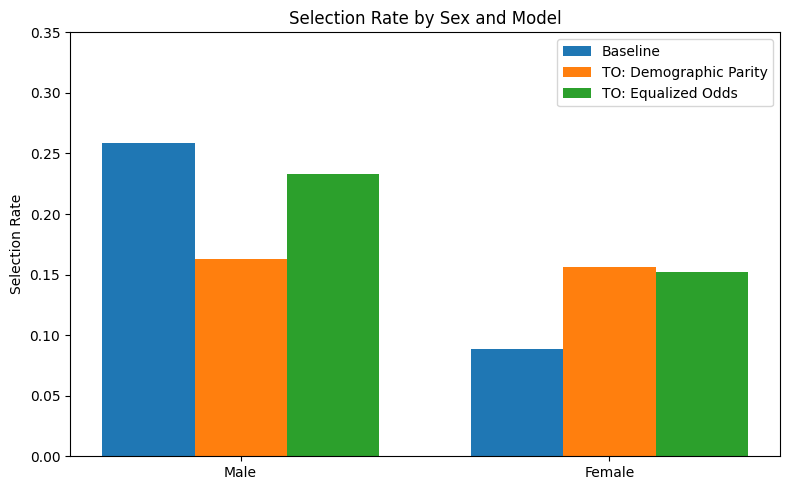

Plot saved : selection_rate_by_sex.png
No single model satisfies both fairness definitions.


In [21]:
# 4. Generate and save the selection rates visualization
labels = ['Male', 'Female']
baseline_rates = [sel_m_base, sel_f_base]
dp_rates = [sel_m_dp, sel_f_dp]
eo_rates = [sel_m_eo, sel_f_eo]

x = np.arange(len(labels))
width = 0.25

fig, ax = plt.subplots(figsize=(8, 5))
rects1 = ax.bar(x - width, baseline_rates, width, label='Baseline')
rects2 = ax.bar(x, dp_rates, width, label='TO: Demographic Parity')
rects3 = ax.bar(x + width, eo_rates, width, label='TO: Equalized Odds')

ax.set_ylabel('Selection Rate')
ax.set_title('Selection Rate by Sex and Model')
ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylim(0, 0.35)
ax.legend()

fig.tight_layout()
plt.savefig('selection_rate_by_sex.png')
plt.show()

print("Plot saved : selection_rate_by_sex.png")
print("No single model satisfies both fairness definitions.")

### Answers to Bias Audit and Mitigation Questions

#### **Q1. (Tasks 1–2) Overall accuracy, group metrics, and disadvantaged group**
* **Overall Accuracy:** **85.41%** (0.8541)
* **Group Metrics by Sex:**
  * **Male:**
    * **Selection Rate:** 25.90% (0.2590)
    * **True Positive Rate (TPR):** 62.81% (0.6281)
    * **False Positive Rate (FPR):** 9.17% (0.0917)
  * **Female:**
    * **Selection Rate:** 8.86% (0.0886)
    * **True Positive Rate (TPR):** 55.86% (0.5586)
    * **False Positive Rate (FPR):** 2.75% (0.0275)
* **Disadvantaged Group:** **Female**. Women have a significantly lower selection rate (only 8.86% are predicted to earn >50K compared to 25.90% of men) and a lower TPR (55.86% compared to 62.81%), meaning qualified women are less likely to be correctly identified as high earners by the model.

---

#### **Q2. (Task 3) Fairness metrics, 4/5ths rule, and source of bias**
* **Fairness Metrics (Baseline):**
  * **Demographic Parity Difference:** 0.1704
  * **Demographic Parity Ratio (Disparate Impact):** 0.3422
  * **Equalized Odds Difference:** 0.0696
* **Does the model pass the four-fifths (80%) rule?** **No**. The demographic parity ratio of **0.3422** is well below the 0.80 threshold. For the model to pass, the selection rate of the protected group must be at least 80% of the selection rate of the majority group.
* **Why is there bias even though "sex" was not used as a feature?**
  This is due to **redundant encodings (or proxy variables)**. Other features (e.g., `occupation`, `marital.status`, `relationship` like 'husband' vs 'wife', and `hours.per.week`) are strongly correlated with gender due to historical and societal patterns. Even when the explicit "sex" column is dropped, the model reconstructs the underlying sensitive attribute from these proxy variables, perpetuating the systemic bias present in the training data.

---

#### **Q3. (Tasks 4–5) Comparison of the two ThresholdOptimizer results**
* **Case 1: Demographic Parity Optimizer**
  * This mitigated model achieved near-perfect demographic parity, reducing the Demographic Parity Difference to **0.01** (selection rates equalized at ~16% for both groups).
  * **Effect on other metric:** The Equalized Odds Difference shot up drastically from **0.07** in the baseline to **0.32**. This shows that forcing equal selection rates severely disrupted error-rate parity (TPRs and FPRs became highly imbalanced across groups).
* **Case 2: Equalized Odds Optimizer**
  * This mitigated model minimized the Equalized Odds Difference down to **0.02** (bringing TPRs and FPRs close to parity across groups).
  * **Effect on other metric:** The Demographic Parity Difference remained at **0.08** (with a 23% selection rate for men and 15% for women). This highlights the fundamental trade-off in mathematical definitions of fairness; you cannot perfectly satisfy both simultaneously.

---

#### **Q4. (Task 6) Trade-offs, Credit-Card recommendation, and limitation**
* **Accuracy Loss:**
  * **Baseline Accuracy:** 85.41%
  * **Demographic Parity Mitigated Accuracy:** 83.41% (Loss of **2.00%**)
  * **Equalized Odds Mitigated Accuracy:** 83.72% (Loss of **1.69%**)
* **Recommendation for Credit-Card Offers:**
  I recommend the **Equalized Odds** mitigation. For financial products like credit cards, individuals with the same underlying financial qualification should have an equal probability of being approved regardless of gender. Equalized Odds ensures that qualified women and qualified men (true positives) are treated equally and that unqualified applicants face similar false positive rates. Demographic parity, on the other hand, might force approvals for unqualified applicants or deny highly qualified applicants just to force equal ratios.
* **Limitation of the ThresholdOptimizer method:**
  A major limitation of this post-processing method is that it **requires explicit access to the sensitive attribute (gender) at prediction/inference time** to apply different decision thresholds for each group. In many real-world, highly regulated industries (such as banking, insurance, or hiring), collecting or utilizing sensitive characteristics during the final decision phase is legally prohibited.